In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from mlxtend.plotting import plot_decision_regions

In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
from sklearn.datasets import make_circles

In [5]:
X , y = make_circles(n_samples=100 , noise=0.1)

<Axes: >

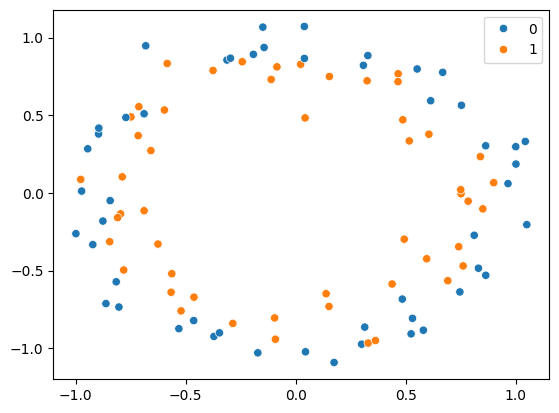

In [6]:
sns.scatterplot(x = X[:,0] , y = X[:,1] , hue=y)

In [7]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2,random_state=42)

In [8]:
model = Sequential()


model.add(Dense(units=256 , activation='relu' , input_shape=(2,)))
model.add(Dense(units=1 , activation='sigmoid'))

C:\Users\Predator\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape              ┃        Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ dense (Dense)                      │ (None, 256)               │            768 │
├────────────────────────────────────┼───────────────────────────┼────────────────┤
│ dense_1 (Dense)                    │ (None, 1)                 │            257 │
└────────────────────────────────────┴───────────────────────────┴────────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(optimizer = 'adam' , loss= 'binary_crossentropy' , metrics = ['accuracy'])

In [15]:
history = model.fit(x = X_train , y=y_train , validation_data = (X_test , y_test) , epochs = 1000 )

Epoch 1/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.5250 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6997
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5375 - loss: 0.6901 - val_accuracy: 0.5000 - val_loss: 0.7002
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5375 - loss: 0.6886 - val_accuracy: 0.4500 - val_loss: 0.7018
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5750 - loss: 0.6880 - val_accuracy: 0.3500 - val_loss: 0.7028
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5125 - loss: 0.6872 - val_accuracy: 0.3500 - val_loss: 0.7056
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5250 - loss: 0.6860 - val_accuracy: 0.3500 - val_loss: 0.7070
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5625 - loss: 0.6852 - val_accuracy: 0.3500 - val_loss: 0.7085
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5625 - loss: 0.6843 - val_accuracy: 0.3500 - 

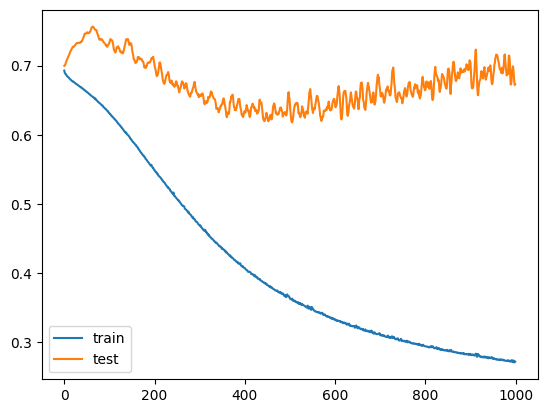

In [17]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


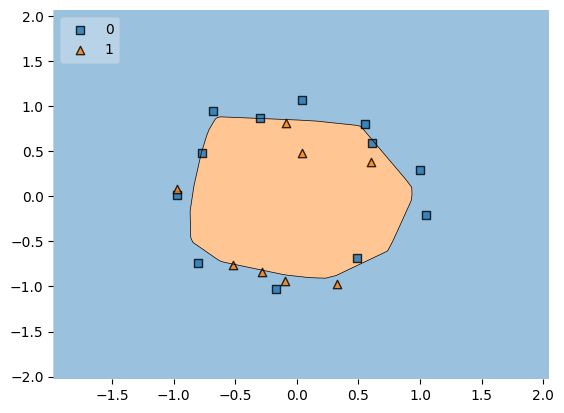

In [20]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()

## Early Stopping

In [22]:
model1 = Sequential()

model1.add(Dense(units=256 , activation='relu' , input_shape=(2,)))
model1.add(Dense(units=1 , activation='sigmoid'))

C:\Users\Predator\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model1.compile(optimizer = 'adam' , loss= 'binary_crossentropy' , metrics = ['accuracy'])

In [43]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="min",
    baseline=None,
    restore_best_weights=False
)

In [44]:
history1 = model1.fit(x = X_train , y = y_train , validation_data = (X_test , y_test) , epochs=1000 , verbose=1 , callbacks=callback)

Epoch 1/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.7125 - loss: 0.6183 - val_accuracy: 0.5000 - val_loss: 0.7260
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7250 - loss: 0.6177 - val_accuracy: 0.5000 - val_loss: 0.7234
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.7375 - loss: 0.6171 - val_accuracy: 0.5000 - val_loss: 0.7213
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7375 - loss: 0.6168 - val_accuracy: 0.5000 - val_loss: 0.7207
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7500 - loss: 0.6157 - val_accuracy: 0.5500 - val_loss: 0.7202
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.7500 - loss: 0.6155 - val_accuracy: 0.5500 - val_loss: 0.7197
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.7500 - loss: 0.6145 - val_accuracy: 0.5500 - val_loss: 0.7193
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.7500 - loss: 0.6137 - val_accuracy: 0.5500 - v

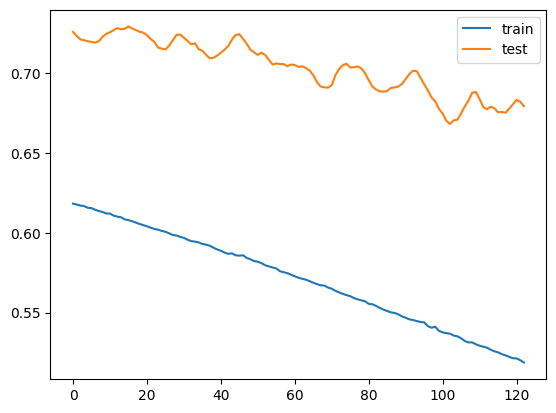

In [45]:
plt.plot(history1.history['loss'], label='train')
plt.plot(history1.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 10s 988us/step


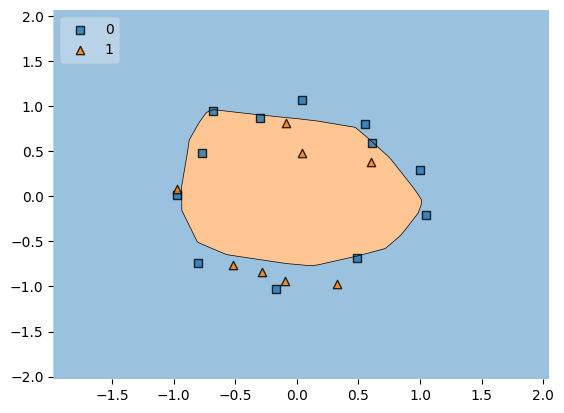

In [46]:
plot_decision_regions(X_test, y_test.ravel(), clf = model1, legend=2)
plt.show()